## Kernel Trick in SVM

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.axes._axes import _log as matplotlib_axes_logger
from mpl_toolkits import mplot3d
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from matplotlib.colors import ListedColormap

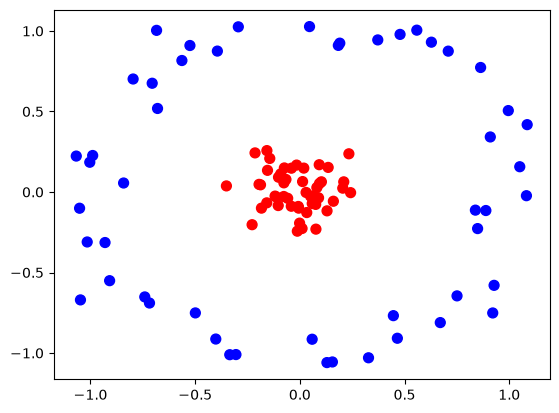

In [5]:

from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='bwr')

In [6]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20)

In [ ]:
# linear data se check 
classifier = SVC(kernel="linear")
classifier.fit(X_train, y_train.ravel())
y_pred = classifier.predict(X_test)

In [8]:

from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.55

In [9]:

zero_one_colourmap = ListedColormap(('blue', 'red'))
def plot_decision_boundary(X, y, clf):
    X_set, y_set = X, y
    X1, X2 = np.meshgrid(np.arange(start = X_set[:, 0].min() - 1, 
                                 stop = X_set[:, 0].max() + 1, 
                                 step = 0.01),
                       np.arange(start = X_set[:, 1].min() - 1, 
                                 stop = X_set[:, 1].max() + 1, 
                                 step = 0.01))
  
    plt.contourf(X1, X2, clf.predict(np.array([X1.ravel(), 
                                             X2.ravel()]).T).reshape(X1.shape),
               alpha = 0.75, 
               cmap = zero_one_colourmap)
    plt.xlim(X1.min(), X1.max())
    plt.ylim(X2.min(), X2.max())
    for i, j in enumerate(np.unique(y_set)):
        plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                c = (zero_one_colourmap)(i), label = j)
    plt.title('SVM Decision Boundary')
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.legend()
    return plt.show()

C:\Users\Alok Kumar\AppData\Local\Temp\ipykernel_7412\2475872515.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


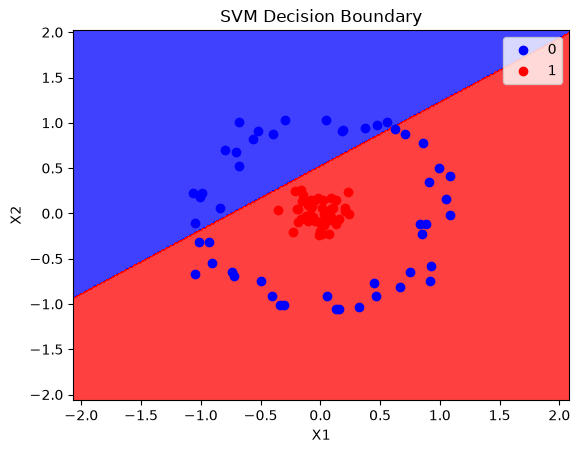

In [10]:

plot_decision_boundary(X, y, classifier)

In [ ]:

def plot_3d_plot(X, y):
    r = np.exp(-(X ** 2).sum(1))  # rbf = e-x2
    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=100, cmap='bwr')
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.set_zlabel('y')
    return ax


<Axes3D: xlabel='X1', ylabel='X2', zlabel='y'>

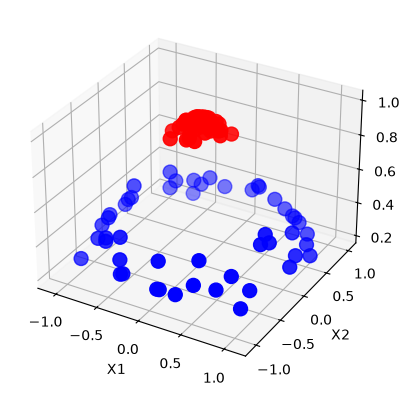

In [12]:

plot_3d_plot(X,y)

In [26]:

rbf_classifier = SVC(kernel="poly",degree =2)  # Support Vector Classifier
rbf_classifier.fit(X_train, y_train)
y_pred = rbf_classifier.predict(X_test)

In [27]:

accuracy_score(y_test, y_pred)

1.0

C:\Users\Alok Kumar\AppData\Local\Temp\ipykernel_7412\2475872515.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


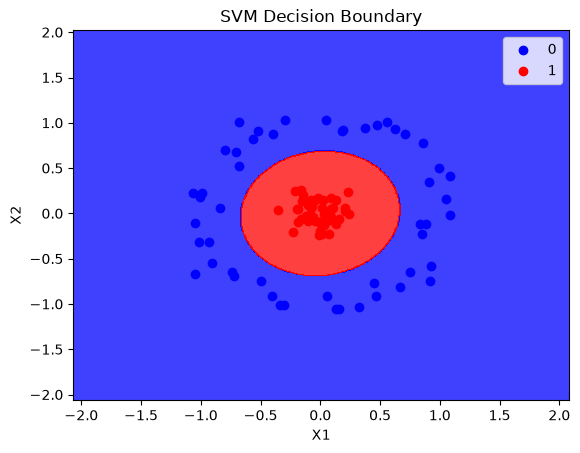

In [28]:

plot_decision_boundary(X, y, rbf_classifier)

In [29]:

poly_classifier = SVC(kernel="poly",degree=2)
poly_classifier.fit(X_train, y_train)
y_pred = poly_classifier.predict(X_test)

In [30]:

accuracy_score(y_test, y_pred)

1.0

C:\Users\Alok Kumar\AppData\Local\Temp\ipykernel_7412\2475872515.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],


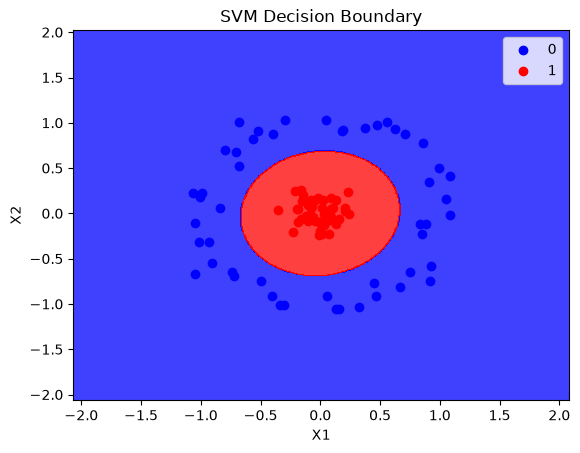

In [31]:

plot_decision_boundary(X, y, poly_classifier)

In [19]:
X

array([[-0.00739696, -0.08990366],
       [-0.30518382, -1.00952676],
       [-1.05189091, -0.10085755],
       [-0.70515346,  0.67528053],
       [ 0.24239151, -0.00411519],
       [-0.52494224,  0.90964701],
       [ 0.07678557, -0.23074661],
       [ 0.88834555, -0.11506075],
       [ 0.15544084, -1.0554794 ],
       [-0.01202446, -0.24336297],
       [-0.2280225 , -0.20316257],
       [ 0.13524491,  0.15266807],
       [-0.7962176 ,  0.7016189 ],
       [ 0.10292596,  0.06323287],
       [-0.0767372 , -0.02799461],
       [-0.05811099, -0.03917233],
       [ 0.20968346,  0.06300485],
       [ 0.0937097 ,  0.05251976],
       [ 0.92761964, -0.57968399],
       [-0.5632635 ,  0.81644711],
       [ 0.47857918,  0.97862787],
       [ 0.92116669, -0.75118263],
       [ 0.44664688, -0.76792029],
       [ 0.08932095, -0.03628473],
       [-0.18787629,  0.04451415],
       [ 0.01056898, -0.22671441],
       [-1.01550931, -0.31035671],
       [ 0.02975705, -0.002905  ],
       [-0.35071639,

In [20]:

np.exp(-(X**2)).sum(1)

array([1.9918952 , 1.27197217, 1.32060219, 1.24201758, 1.9429221 ,
       1.19630285, 1.94226996, 1.44107545, 1.304359  , 1.9423496 ,
       1.9088995 , 1.95883707, 1.14172347, 1.98547175, 1.99334532,
       1.99509551, 1.95302365, 1.98850241, 1.13755893, 1.24159581,
       1.17906804, 0.99680811, 1.37363834, 1.99073779, 1.96333864,
       1.94978748, 1.2647299 , 1.99910647, 1.88284006, 1.15580933,
       1.2318757 , 1.97081835, 1.97677375, 1.9714106 , 1.98232581,
       1.96967287, 1.99266389, 1.25426042, 1.98623558, 1.99141393,
       1.21877444, 1.09477851, 1.97788645, 1.99545746, 1.26653894,
       1.40342748, 1.96328752, 1.30954613, 1.22882696, 1.3089405 ,
       1.91163412, 1.34855948, 1.24450447, 1.09622829, 1.93712912,
       1.89194226, 1.34607249, 0.99127076, 1.99052464, 1.97913118,
       0.97189624, 1.98994877, 1.98952691, 1.89800568, 1.97249125,
       1.1456736 , 1.43610753, 1.32566162, 1.98837623, 1.28056891,
       1.32132539, 1.99565739, 1.27126249, 1.99159276, 1.95829

In [21]:

X_new=np.exp(-(X**2))

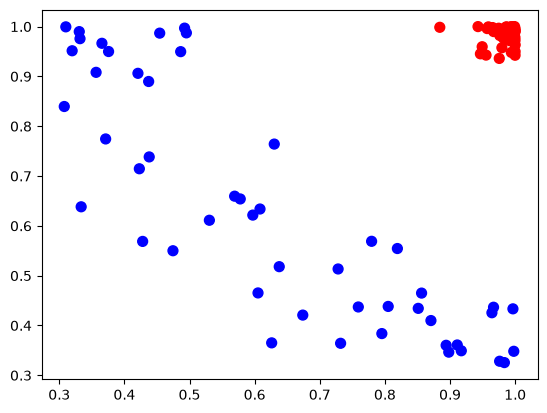

In [22]:

plt.scatter(X_new[:, 0], X_new[:, 1], c=y, s=50, cmap='bwr')